In [2]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import pysdds

from opal import load_single_screen

# Screen at 1 mm

In [3]:
sim_dir = "../data/opal/saved_runs/1nc_yag5"
#sim_dir = "opal_sim/tmp_run/"

In [4]:
cathode_screen = load_single_screen(os.path.join(sim_dir, "cathode_screen.h5"))
cathode_screen

{'data': {'id': array([     4,     14,     18, ..., 262112, 262143, 256543]),
  'm': array([12.16661294, 12.16661294, 12.16661294, ..., 12.16661294,
         12.16661294, 12.16661294]),
  'px': array([-0.00515486, -0.00369299, -0.00877948, ..., -0.00010776,
          0.00119276,  0.00270588]),
  'py': array([-0.00207073, -0.00118475, -0.00245306, ...,  0.00695583,
          0.01536219,  0.0112777 ]),
  'pz': array([0.42456662, 0.4249613 , 0.41949815, ..., 0.42026292, 0.42389489,
         0.43094646]),
  'q': array([-3.81469727e-15, -3.81469727e-15, -3.81469727e-15, ...,
         -3.81469727e-15, -3.81469727e-15, -3.81469727e-15]),
  'time': array([1.25004884e-11, 1.24923211e-11, 1.25646486e-11, ...,
         2.12035303e-11, 2.11402006e-11, 2.08380404e-11]),
  'x': array([-1.22643175e-03, -7.59037133e-04, -1.86890162e-03, ...,
          1.29279235e-04,  1.53295817e-04,  7.71892377e-06]),
  'y': array([-0.00020728, -0.00027142, -0.00033696, ...,  0.0009318 ,
          0.00160166,  0.0011

In [5]:
cathode_screen['attributes']['SPOS']

array([0.001])

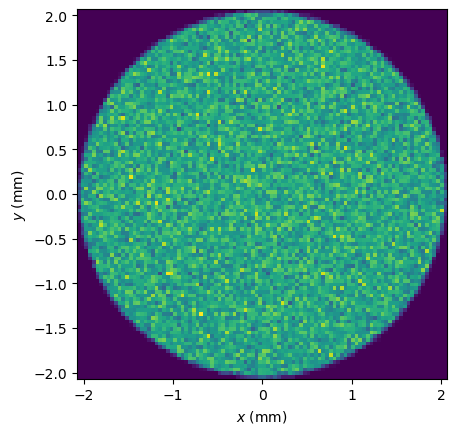

In [6]:
fig, ax = plt.subplots()
ax.hist2d(
    cathode_screen['data']['x']*1e3, 
    cathode_screen['data']['y']*1e3, 
    bins=100
)
ax.set_xlabel('$x$ (mm)')
ax.set_ylabel('$y$ (mm)')
ax.set_aspect('equal')
plt.show()

# Beam stats along beamline

In [7]:
# load beam stats
sdds = pysdds.read(os.path.join(sim_dir, 'input.sdds'))
sdds.column_names

/Users/jp/Repositories/pysdds/pysdds/readers/readers.py:2623: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_table(buf, encoding="ascii", **opts)


['t',
 's',
 'numParticles',
 'charge',
 'energy',
 'rms_x',
 'rms_y',
 'rms_s',
 'rms_px',
 'rms_py',
 'rms_ps',
 'emit_x',
 'emit_y',
 'emit_s',
 'mean_x',
 'mean_y',
 'mean_s',
 'ref_x',
 'ref_y',
 'ref_z',
 'ref_px',
 'ref_py',
 'ref_pz',
 'max_x',
 'max_y',
 'max_s',
 'xpx',
 'ypy',
 'zpz',
 'Dx',
 'DDx',
 'Dy',
 'DDy',
 'Bx_ref',
 'By_ref',
 'Bz_ref',
 'Ex_ref',
 'Ey_ref',
 'Ez_ref',
 'dE',
 'dt',
 'partsOutside',
 'DebyeLength',
 'plasmaParameter',
 'temperature',
 'rmsDensity']

In [8]:
stats = sdds.columns_to_df()
stats

,t,s,numParticles,charge,energy,rms_x,rms_y,rms_s,rms_px,rms_py,...,Ex_ref,Ey_ref,Ez_ref,dE,dt,partsOutside,DebyeLength,plasmaParameter,temperature,rmsDensity
0,-0.004186,0.000000,47,-1.792908e-13,0.000002,0.000967,0.001039,2.750785e-08,0.001337,0.001384,...,0.0,0.0,-45.551436,0.000001,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
1,-0.004011,0.000000,1056,-4.028320e-12,0.000004,0.000995,0.000991,6.374672e-08,0.001344,0.001351,...,0.0,0.0,-45.609745,0.000003,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
2,-0.003837,0.000000,5643,-2.152634e-11,0.000006,0.000995,0.000999,1.265019e-07,0.001362,0.001345,...,0.0,0.0,-45.667962,0.000006,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
3,-0.003663,0.000000,11233,-4.285049e-11,0.000013,0.001002,0.000996,2.536241e-07,0.001354,0.001344,...,0.0,0.0,-45.726086,0.000012,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
4,-0.003488,0.000000,16978,-6.476593e-11,0.000024,0.000999,0.001001,4.522470e-07,0.001351,0.001350,...,0.0,0.0,-45.784118,0.000021,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
845,49.276325,14.757700,262144,-1.000000e-09,41.929219,0.001735,0.001706,8.125465e-04,0.023752,0.001779,...,0.0,0.0,0.000000,0.052597,0.010000,0.0,0.000039,125.867018,162.555435,5.137969e+14
846,49.376325,14.787677,262144,-1.000000e-09,41.929211,0.001726,0.001706,8.125425e-04,0.023744,0.001777,...,0.0,0.0,0.000000,0.052581,0.010000,0.0,0.000039,125.420647,162.451690,5.164705e+14
847,49.476325,14.817654,262144,-1.000000e-09,41.929204,0.001718,0.001706,8.125384e-04,0.023737,0.001775,...,0.0,0.0,0.000000,0.052565,0.010000,0.0,0.000039,124.974132,162.347749,5.191698e+14
848,49.576325,14.847631,262144,-1.000000e-09,41.929196,0.001709,0.001706,8.125344e-04,0.023729,0.001773,...,0.0,0.0,0.000000,0.052548,0.010000,0.0,0.000038,124.530031,162.243609,5.218738e+14


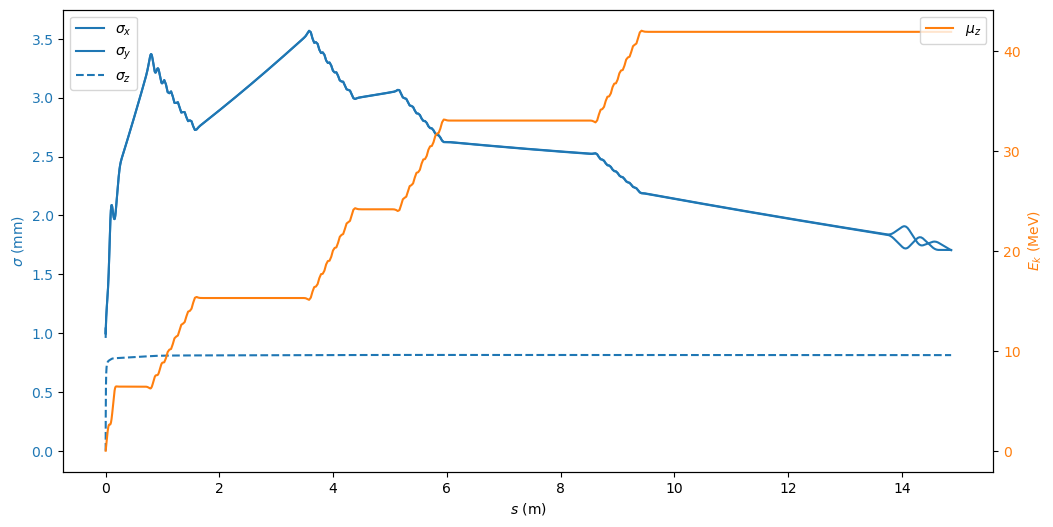

In [9]:
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(stats['s'], stats['rms_x']*1e3, color=colors[0], label='$\sigma _x$')
ax.plot(stats['s'], stats['rms_y']*1e3, color=colors[0], label='$\sigma _y$')
ax.plot(stats['s'], stats['rms_s']*1e3, color=colors[0], linestyle='--', label='$\sigma _z$')
ax.legend(loc='upper left')
ax.set_xlabel('$s$ (m)')
ax.set_ylabel('$\sigma$ (mm)', color=colors[0])
ax.tick_params(axis='y', labelcolor=colors[0])

ax2 = ax.twinx()
ax2.plot(stats['s'], stats['energy'], color=colors[1], label='$\mu _z$')
ax2.legend(loc='upper right')
ax2.set_ylabel('$E_k$ (MeV)', color=colors[1])
ax2.tick_params(axis='y', labelcolor=colors[1])

plt.show()

In [10]:
# include element positions for better plotting

# load design path
col_names = ['s', 'z']
design_path = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_DesignPath.dat'), 
    sep='\s+',
    skiprows=1,
    usecols=[0,3],
    names=col_names
)

# define function that transforms s to z using the design path
def z_to_s(z_value):
    idx = np.abs(design_path['z'] - z_value).argmin(axis=-1)
    return design_path['s'][idx]
z_to_s = np.vectorize(z_to_s)

# load element positions
col_names = ['label', 'z', 'x', 'y']
ele_pos = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_ElementPositions.txt'), 
    sep='\s+', 
    index_col=0, 
    names=col_names
)
# get s coordinate for each element
ele_pos['s'] = z_to_s(ele_pos['z'])
ele_pos

,z,x,y,s
label,,,,
BEGIN: CATHODE,0.000000,0,0,0.000458
END: CATHODE,0.050000,0,0,0.051189
BEGIN: YAG5,14.765200,0,0,14.764947
END: YAG5,14.775200,0,0,14.773940
BEGIN: YAG4,11.372000,0,0,11.371543
END: YAG4,11.382000,0,0,11.380536
BEGIN: DQ4,13.740200,0,0,13.739731
END: DQ4,13.860200,0,0,13.859639
BEGIN: DQ5,14.005200,0,0,14.006527


In [11]:
# elements I want to plot
elements = {
    'linacs': ['GUN', 'LINAC_1', 'LINAC_2', 'LINAC_3', 'LINAC_5'],
#    'dipoles': ['ED1', 'ED2', 'ED3', 'ED4'],
    'quads':  ['DQ4', 'DQ5', 'DQ6', 'DQ7'],
#    'rquads':  ['RQ1', 'RQ2'],
}

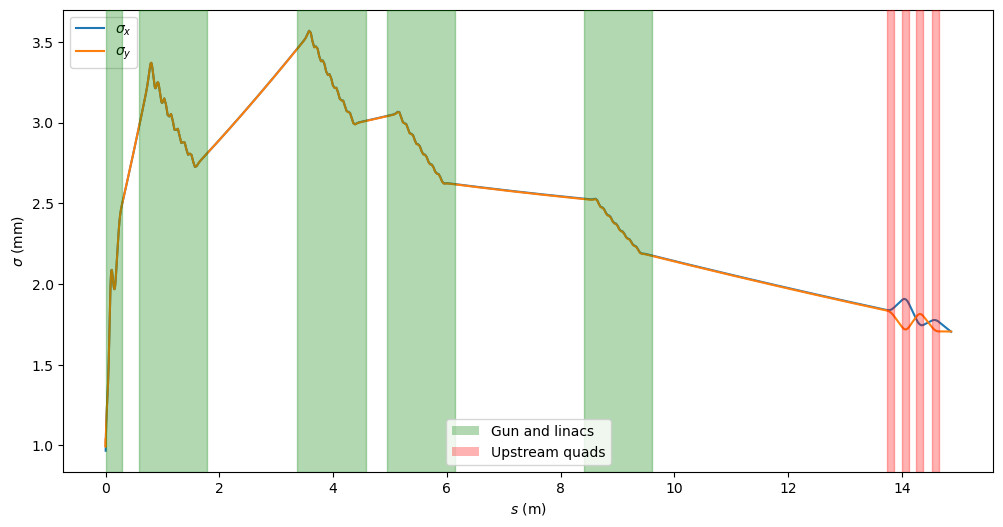

In [12]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(stats['s'], stats['rms_x']*1e3, label='$\sigma _x$')
ax.plot(stats['s'], stats['rms_y']*1e3, label='$\sigma _y$')
ax.legend(loc='upper left')
ax.set_xlabel('$s$ (m)')
ax.set_ylabel('$\sigma$ (mm)')

ax3 = ax.twinx()
for linac in elements['linacs']:
    begin = ele_pos.at[f'BEGIN: {linac}', 'z']
    end = ele_pos.at[f'END: {linac}', 'z']
    ax3.axvspan(begin, end, alpha=0.3 , color='green')
for quad in elements['quads']:
    begin = ele_pos.at[f'BEGIN: {quad}', 'z']
    end = ele_pos.at[f'END: {quad}', 'z']
    ax3.axvspan(begin, end, alpha=0.3 , color='red')
ax3.axis('off')
legend_elements = [
    Patch(facecolor='green', alpha=0.3),
    Patch(facecolor='red', alpha=0.3),
#    Patch(facecolor='blue', alpha=0.3),
#    Patch(facecolor='red', alpha=0.3),
]
legend_labels = [
    'Gun and linacs',
    'Upstream quads',
#    'Dipoles',
#    'Reversing quads',
]
ax3.legend(legend_elements, legend_labels, loc='lower center')
plt.show()

In [29]:
stats['energy']

0       0.000002
1       0.000004
2       0.000006
3       0.000013
4       0.000024
         ...    
845    41.929219
846    41.929211
847    41.929204
848    41.929196
849    41.929191
Name: energy, Length: 850, dtype: float64

# Phase space at YAG4

In [13]:
yag4 = load_single_screen(os.path.join(sim_dir, 'YAG4.h5'))
yag5 = load_single_screen(os.path.join(sim_dir, 'YAG5.h5'))

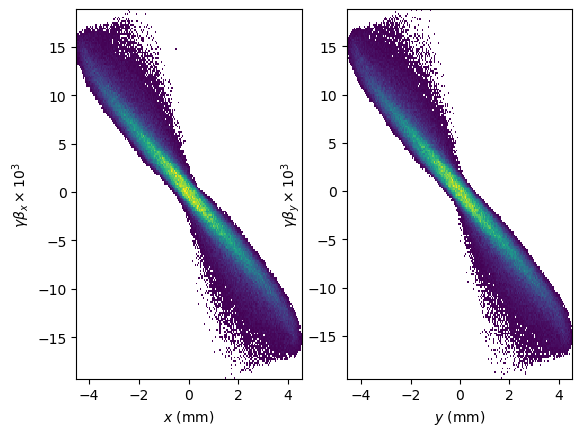

In [28]:
fig, axs = plt.subplots(1, 2)
axs[0].hist2d(
    yag4['data']['x']*1e3, 
    yag4['data']['px']*1e3,
    bins=200,
    cmin=1
)
axs[0].set_xlabel('$x$ (mm)')
axs[0].set_ylabel('$\gamma \\beta_x \\times 10^3$')
axs[1].hist2d(
    yag4['data']['y']*1e3, 
    yag4['data']['py']*1e3,
    bins=200,
    cmin=1
)
axs[1].set_xlabel('$y$ (mm)')
axs[1].set_ylabel('$\gamma \\beta_y \\times 10^3$')
plt.show()

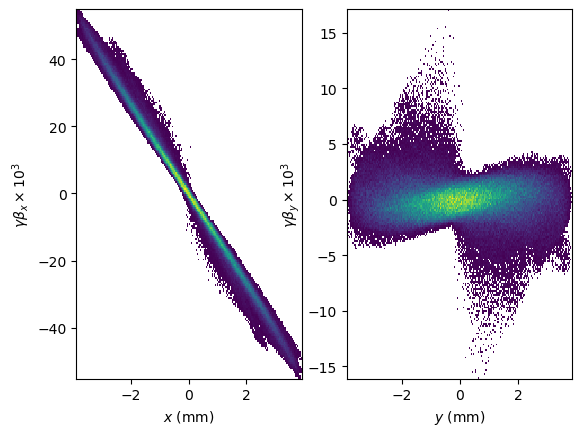

In [27]:
fig, axs = plt.subplots(1, 2)
axs[0].hist2d(
    yag5['data']['x']*1e3, 
    yag5['data']['px']*1e3,
    bins=200,
    cmin=1
)
axs[0].set_xlabel('$x$ (mm)')
axs[0].set_ylabel('$\gamma \\beta_x \\times 10^3$')
axs[1].hist2d(
    yag5['data']['y']*1e3, 
    yag5['data']['py']*1e3,
    bins=200,
    cmin=1
)
axs[1].set_xlabel('$y$ (mm)')
axs[1].set_ylabel('$\gamma \\beta_y \\times 10^3$')
plt.show()

In [16]:
yag4

{'data': {'id': array([ 38213,  63003,  40614, ...,  98993, 209791, 225191]),
  'm': array([12.16661294, 12.16661294, 12.16661294, ..., 12.16661294,
         12.16661294, 12.16661294]),
  'px': array([0.000797  , 0.00184103, 0.00076336, ..., 0.00128804, 0.0006352 ,
         0.00072874]),
  'py': array([ 0.0009728 ,  0.00178165,  0.00069123, ..., -0.00519355,
         -0.00268164,  0.00085765]),
  'pz': array([82.88977085, 82.91721782, 82.89119382, ..., 82.99486907,
         83.18592658, 83.17840666]),
  'q': array([-3.81469727e-15, -3.81469727e-15, -3.81469727e-15, ...,
         -3.81469727e-15, -3.81469727e-15, -3.81469727e-15]),
  'time': array([3.79796944e-08, 3.79807321e-08, 3.79797840e-08, ...,
         3.79821163e-08, 3.79861141e-08, 3.79867574e-08]),
  'x': array([-2.91081836e-04, -9.42061573e-04, -6.71711957e-04, ...,
          1.84966791e-05,  1.83900273e-05,  1.83088299e-05]),
  'y': array([-6.76732802e-05, -9.67821729e-04, -4.45114980e-04, ...,
          2.06850395e-03,  4.9

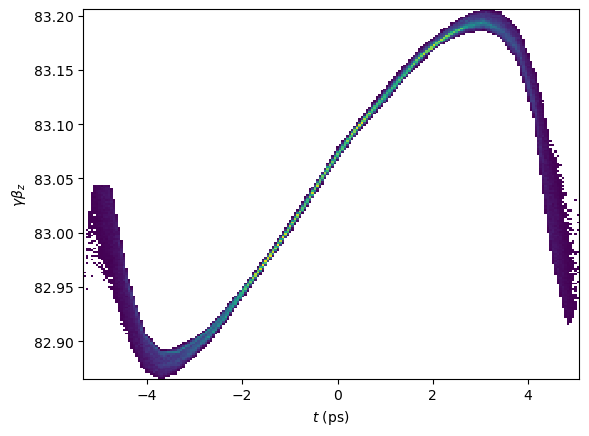

In [17]:
plt.hist2d(
    (yag4['data']['time'] - yag4['data']['time'].mean())*1e12, 
    yag4['data']['pz'],
    bins=200,
    cmin=1
)
plt.xlabel('$t$ (ps)')
plt.ylabel('$\gamma \\beta_z$')
plt.show()

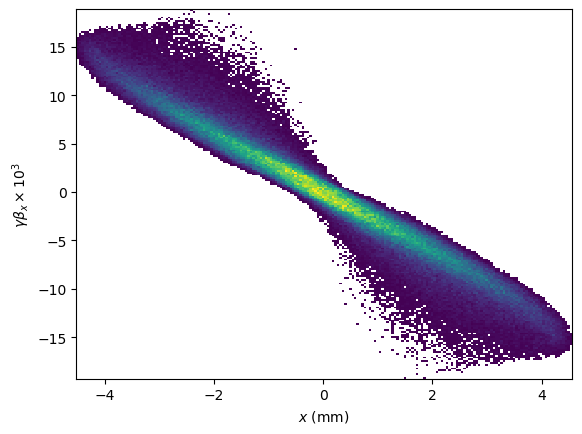

In [18]:
plt.hist2d(
    yag4['data']['x']*1e3, 
    yag4['data']['px']*1e3,
    bins=200,
    cmin=1
)
plt.xlabel('$x$ (mm)')
plt.ylabel('$\gamma \\beta_x \\times 10^3$')
plt.show()

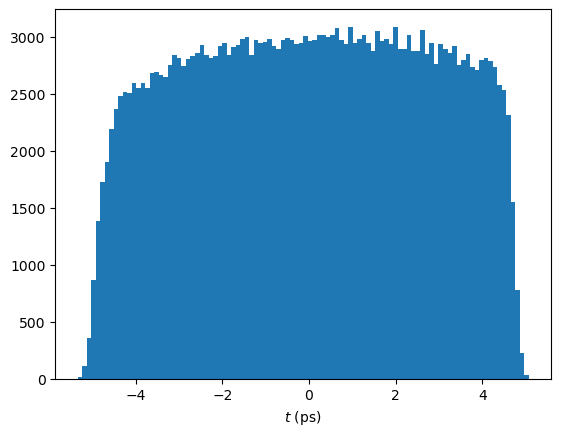

In [19]:
plt.hist(
    (yag4['data']['time']-yag4['data']['time'].mean())*1e12,
    bins=100
)
plt.xlabel('$t$ (ps)')
plt.show()